# Expected calibration error (ECE) of the activity uncertainty

Reviewer points R2.5 and R3.5 ask for the exact ECE definition and why the main text (Fig. 7, ≈0.15) and the SI (Fig. S4, ≈1.4) differ.

**Definition used in Fig. 7** (reproduced below to 3 decimals):

- σᵢ = √(predicted variance) for each test complex, in **z-units** (activities are z-scored with the training mean/std, so the errors are in the same units).
- The test sets of the 5 folds are **pooled**.
- σ is split into **B = 10 equal-count bins** (deciles of σ).
- Per bin b: RMSE_b = √(mean (ŷᵢ − yᵢ)²) and σ̄_b = mean σᵢ.
- ECE = Σ_b (n_b / N) · |RMSE_b − σ̄_b|.

Because the metric is linear in the units, ECE in pIC50 units = ECE in z-units × the training std of pIC50.

Input: the `test_activity_epoch_<e>.csv` files that `RegressionModel` writes for each fold (columns `pred_activity, target_activity, variance, pose, target_pose`).

In [1]:
from pathlib import Path

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
OUTPUT = REPO / "analysis" / "output"
OUTPUT.mkdir(exist_ok=True)

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder with one <run>_fold_<k>/ subfolder per fold; on iris the original paper runs are here
RUNS_DIR = REPO / "kinodata" / "training" / "data_runs_test"

In [2]:
def load_test(run, runs_dir=RUNS_DIR, k_folds=5):
    """Test predictions of all folds of a run, pooled (one row per test complex)."""
    dfs = []
    for k in range(k_folds):
        files = sorted(Path(runs_dir).glob(f"{run}_fold_{k}/test_activity_epoch_*.csv"),
                       key=lambda f: int(re.search(r"epoch_(\d+)", f.name).group(1)))
        if not files:
            raise FileNotFoundError(f"no test CSV for {run} fold {k} in {runs_dir}")
        df = pd.read_csv(files[-1])  # one test file per fold (best checkpoint); latest epoch if several
        df["fold"] = k
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def calibration_table(df, n_bins=10, binning="quantile"):
    """Per-bin count, mean predicted sigma and observed RMSE.
    binning: "quantile" = equal-count bins (paper), "width" = equal-width bins."""
    sigma = np.sqrt(df["variance"].to_numpy())
    sq_err = (df["pred_activity"] - df["target_activity"]).to_numpy() ** 2
    if binning == "quantile":
        edges = np.quantile(sigma, np.linspace(0, 1, n_bins + 1))
    else:
        edges = np.linspace(sigma.min(), sigma.max(), n_bins + 1)
    b = np.clip(np.digitize(sigma, edges[1:-1]), 0, n_bins - 1)
    tab = (pd.DataFrame({"bin": b, "sigma": sigma, "sq_err": sq_err})
           .groupby("bin")
           .agg(n=("sigma", "size"), mean_sigma=("sigma", "mean"), mse=("sq_err", "mean")))
    tab["rmse"] = np.sqrt(tab.pop("mse"))
    return tab


def ece(df, n_bins=10, binning="quantile"):
    tab = calibration_table(df, n_bins, binning)
    return float((tab["n"] * (tab["rmse"] - tab["mean_sigma"]).abs()).sum() / tab["n"].sum())

## Fig. 7: scaffold split, pose-aware vs no-pose

The September 2025 runs (RMSD ≤ 10 Å, ε = 0.10, pose weights 10/7) reproduce the published values and the 60,064 scaffold test complexes.

In [3]:
PAPER_FIG7 = {  # run name: (label, ECE printed in Fig. 7)
    "experiment_ordered_scaffold_new_soft_wa_bcw_wl10_wh7": ("pose-aware", 0.146),
    "experiment_ordered_scaffold_no_pose": ("no-pose", 0.181),
}
fig7 = {run: load_test(run) for run in PAPER_FIG7}
rows = []
for run, (label, paper) in PAPER_FIG7.items():
    value = ece(fig7[run])
    rows.append({"model": label, "run": run, "n_test": len(fig7[run]), "ECE": round(value, 4),
                 "paper": paper, "matches paper": round(value, 3) == paper})
pd.DataFrame(rows)

,model,run,n_test,ECE,paper,matches paper
0,pose-aware,experiment_ordered_scaffold_new_soft_wa_bcw_wl...,60064,0.1461,0.146,True
1,no-pose,experiment_ordered_scaffold_no_pose,60064,0.1805,0.181,True


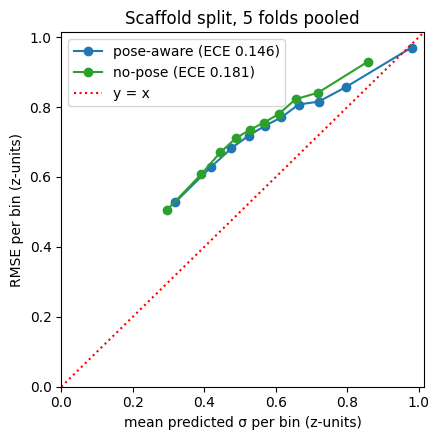

In [4]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
colors = {"pose-aware": "tab:blue", "no-pose": "tab:green"}
for run, (label, _) in PAPER_FIG7.items():
    tab = calibration_table(fig7[run])
    ax.plot(tab["mean_sigma"], tab["rmse"], "o-", color=colors[label], label=f"{label} (ECE {ece(fig7[run]):.3f})")
lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lim, lim, "r:", label="y = x")
ax.set(xlabel="mean predicted σ per bin (z-units)", ylabel="RMSE per bin (z-units)",
       title="Scaffold split, 5 folds pooled", xlim=lim, ylim=lim)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "ece_fig7_scaffold.png", dpi=200)

### Sensitivity to the binning

The values change little with the number of bins, the binning scheme, or averaging per fold instead of pooling. This is worth stating in the response to show the comparison does not depend on the choice.

In [5]:
rows = []
for run, (label, _) in PAPER_FIG7.items():
    df = fig7[run]
    for binning in ["quantile", "width"]:
        for n_bins in [10, 15, 20]:
            per_fold = [ece(g, n_bins, binning) for _, g in df.groupby("fold")]
            rows.append({"model": label, "binning": binning, "bins": n_bins,
                         "pooled": round(ece(df, n_bins, binning), 4),
                         "per-fold mean": round(np.mean(per_fold), 4), "per-fold sd": round(np.std(per_fold, ddof=1), 4)})
pd.DataFrame(rows)

,model,binning,bins,pooled,per-fold mean,per-fold sd
0,pose-aware,quantile,10,0.1461,0.1479,0.0366
1,pose-aware,quantile,15,0.1482,0.1483,0.0370
2,pose-aware,quantile,20,0.1489,0.1495,0.0374
3,pose-aware,width,10,0.1494,0.1510,0.0385
4,pose-aware,width,15,0.1488,0.1512,0.0379
5,pose-aware,width,20,0.1486,0.1507,0.0382
6,no-pose,quantile,10,0.1805,0.1792,0.0487
7,no-pose,quantile,15,0.1801,0.1797,0.0474
8,no-pose,quantile,20,0.1802,0.1788,0.0484
9,no-pose,width,10,0.1825,0.1810,0.0490


## Other run families on iris

- **Nov 2025, 20 Å, ε = 0.02** (`rmsd20_*`): same method, for comparison.
- **SI Fig. S4 (random split)** prints 1.387 / 1.531. These are most likely 0.1387 / 0.1531 (decimal typo). No random-split run on iris reproduces them exactly with this method; the closest candidates are listed. The runs behind Fig. S4 are still unidentified.

In [6]:
OTHER = {
    "rmsd20_scaffold_wl10_wh7": "Nov 2025 scaffold, pose-aware (20 Å, ε 0.02)",
    "rmsd20_scaffold_no_pose": "Nov 2025 scaffold, no-pose (20 Å)",
    "rmsd20_random_wl10_wh7": "Nov 2025 random, pose-aware (20 Å, ε 0.02)",
    "rmsd20_random_no_pose": "Nov 2025 random, no-pose (20 Å)",
    "experiment_random_new_soft_wa_bcw_wl10_wh7": "Aug 2025 random, pose-aware (10 Å)",
    "no_pose": "Jun 2025 random, no-pose (10 Å); closest to S4 no-pose 0.1531",
    "normal_wa_scale_01": "random, pose-aware variant; closest to S4 pose-aware 0.1387",
}
rows = []
for run, desc in OTHER.items():
    try:
        df = load_test(run)
    except FileNotFoundError as e:
        rows.append({"run": run, "what": desc, "n_test": None, "ECE": None, "note": str(e)})
        continue
    rows.append({"run": run, "what": desc, "n_test": len(df), "ECE": round(ece(df), 4), "note": ""})
pd.DataFrame(rows)

,run,what,n_test,ECE,note
0,rmsd20_scaffold_wl10_wh7,"Nov 2025 scaffold, pose-aware (20 Å, ε 0.02)",61568,0.1450,
1,rmsd20_scaffold_no_pose,"Nov 2025 scaffold, no-pose (20 Å)",61568,0.2124,
2,rmsd20_random_wl10_wh7,"Nov 2025 random, pose-aware (20 Å, ε 0.02)",59680,0.1673,
3,rmsd20_random_no_pose,"Nov 2025 random, no-pose (20 Å)",59680,0.1379,
4,experiment_random_new_soft_wa_bcw_wl10_wh7,"Aug 2025 random, pose-aware (10 Å)",59680,0.1589,
5,no_pose,"Jun 2025 random, no-pose (10 Å); closest to S4...",59680,0.1521,
6,normal_wa_scale_01,"random, pose-aware variant; closest to S4 pose...",59680,0.1382,
